# House Price Prediction

I use house details to train and compare regression models for predicting house prices.


## Import libraries


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import time
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import PolynomialFeatures
from sklearn.pipeline import make_pipeline
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

## Part B — Prepare the dataset

Load the data, check missing values, choose features, and split into training and testing sets.


In [2]:
df = pd.read_excel("RealEstate_HousePrice_Dataset_4200.xlsx")
df.head()

,house_id,area_sqft,bedrooms,bathrooms,location_score,age_years,distance_city_km,lot_size_sqft,has_garage,has_pool,renovation_years_ago,house_price_inr
0,100001,1973,5,4,7.6,23,11.9,5220,1,0,0,40275084
1,100002,1560,3,3,6.3,13,15.8,3882,1,0,13,26812029
2,100003,2071,4,3,5.8,9,21.1,4488,0,0,9,29315677
3,100004,2640,5,3,7.7,12,7.9,3614,1,1,4,47712959
4,100005,1498,3,3,3.8,15,24.0,2663,0,0,15,17724566


In [3]:
print(df.shape)
print(df.isnull().sum())

(4200, 12)
house_id                0
area_sqft               0
bedrooms                0
bathrooms               0
location_score          0
age_years               0
distance_city_km        0
lot_size_sqft           0
has_garage              0
has_pool                0
renovation_years_ago    0
house_price_inr         0
dtype: int64


### Q7. Features and target

The input features are house details. The target is `house_price_inr`. I leave out `house_id` because it is only an identifier.


In [4]:
features = ["area_sqft", "bedrooms", "bathrooms", "location_score", "age_years", "distance_city_km", "lot_size_sqft", "has_garage", "has_pool", "renovation_years_ago"]
target = "house_price_inr"
data = df[features + [target]].dropna()
X, y = data[features], data[target]

### Q8. Visualize the data

This scatter plot shows how house area relates to price.


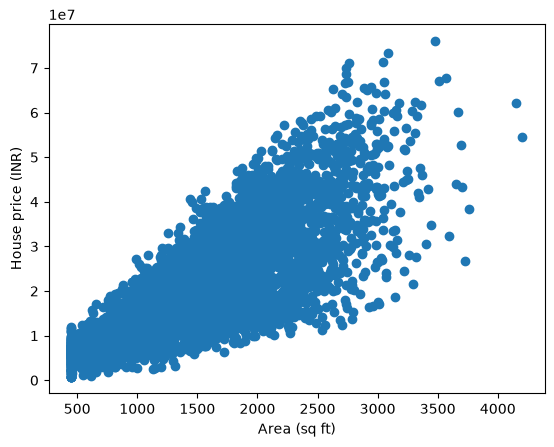

In [5]:
plt.scatter(data["area_sqft"], y)
plt.xlabel("Area (sq ft)"); plt.ylabel("House price (INR)")
plt.show()

### Q9. Train-test split

I use 80% of the data for training and 20% for testing.


In [6]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
print(len(X_train), len(X_test))

3360 840


## Part C — Simple Linear Regression

This model uses only `area_sqft` to predict price.


In [7]:
Xs = data[["area_sqft"]]
ys = data[target]
Xs_train, Xs_test, ys_train, ys_test = train_test_split(Xs, ys, test_size=0.2, random_state=42)
simple = LinearRegression().fit(Xs_train, ys_train)
pred_s = simple.predict(Xs_test)
print("Slope:", simple.coef_[0])
print("Intercept:", simple.intercept_)

Slope: 14788.306111307536
Intercept: -1163519.1764186025


The slope tells me how much the predicted price changes when the area increases by one square foot. The intercept is the model’s predicted price when the area is zero; that value may not be meaningful for a real house, but it is part of the equation.


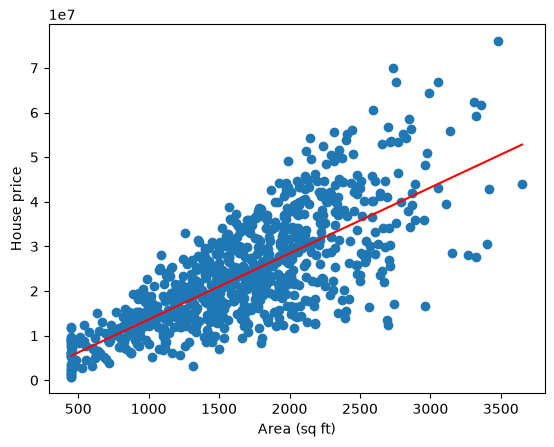

In [8]:
order = np.argsort(Xs_test["area_sqft"].values)
plt.scatter(Xs_test["area_sqft"], ys_test)
plt.plot(Xs_test["area_sqft"].values[order], pred_s[order], color="red")
plt.xlabel("Area (sq ft)"); plt.ylabel("House price")
plt.show()

### Q12. Check the assumptions

I look at the scatter plot and residual plot to check the model. A straight-line pattern should be reasonable for the data, and residuals should be spread around zero without a clear curve or funnel shape. These plots can point out problems, but they cannot prove that every assumption is satisfied.


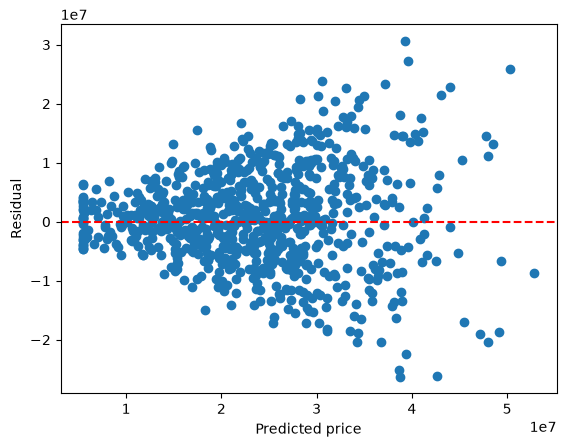

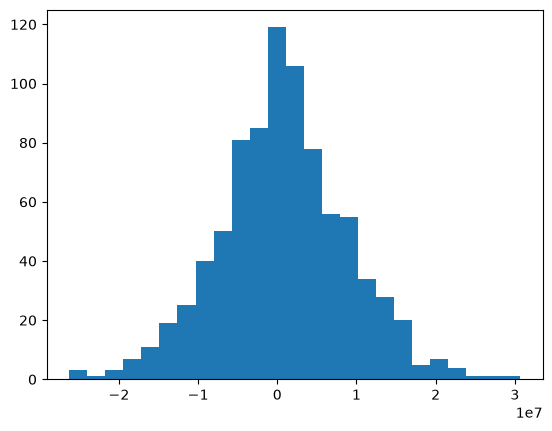

In [9]:
residuals = ys_test - pred_s
plt.scatter(pred_s, residuals); plt.axhline(0, color="red", linestyle="--")
plt.xlabel("Predicted price"); plt.ylabel("Residual")
plt.show()
plt.hist(residuals, bins=25); plt.show()

## Part D — Evaluation metrics

MAE and RMSE show prediction error; R² shows how much price variation the model explains.


In [10]:
mse_s = mean_squared_error(ys_test, pred_s)
mae_s = mean_absolute_error(ys_test, pred_s)
rmse_s = np.sqrt(mse_s)
r2_s = r2_score(ys_test, pred_s)
adj_s = 1 - (1-r2_s)*(len(ys_test)-1)/(len(ys_test)-Xs_test.shape[1]-1)
print("MSE:", mse_s, "\nMAE:", mae_s, "\nRMSE:", rmse_s, "\nR2:", r2_s, "\nAdjusted R2:", adj_s)

MSE: 66989260021849.47 
MAE: 6294593.696131912 
RMSE: 8184696.696997969 
R2: 0.5625199587991578 
Adjusted R2: 0.5619979062440257


## Part E — Multiple Linear Regression

This model uses several house features. I compare its test results with the simple model.


In [11]:
multiple = LinearRegression().fit(X_train, y_train)
pred_m = multiple.predict(X_test)
rmse_m = np.sqrt(mean_squared_error(y_test, pred_m))
print("MAE:", mean_absolute_error(y_test, pred_m))
print("RMSE:", rmse_m)
print("R2:", r2_score(y_test, pred_m))

MAE: 2604991.406155696
RMSE: 3548650.2904805583
R2: 0.917760687750989


The multiple regression model has more information available, so it may predict better than the simple model. However, adding more features does not guarantee a better result. I use the test metrics below to make the comparison instead of assuming one model is best.


In [12]:
print(pd.DataFrame({"Model":["Simple","Multiple"], "RMSE":[rmse_s, rmse_m], "R2":[r2_s, r2_score(y_test, pred_m)]}))

      Model          RMSE        R2
0    Simple  8.184697e+06  0.562520
1  Multiple  3.548650e+06  0.917761


## Part F — Polynomial Regression

Polynomial models can fit curved patterns. I compare degree 2 and degree 3.


In [13]:
poly_scores = []
for d in [2, 3]:
    model = make_pipeline(PolynomialFeatures(d, include_bias=False), LinearRegression())
    model.fit(Xs_train, ys_train)
    p = model.predict(Xs_test)
    poly_scores.append([d, mean_absolute_error(ys_test, p), np.sqrt(mean_squared_error(ys_test, p)), r2_score(ys_test, p)])
poly_df = pd.DataFrame(poly_scores, columns=["Degree", "MAE", "RMSE", "R2"])
poly_df

,Degree,MAE,RMSE,R2
0,2,6.292395e+06,8.183089e+06,0.562692
1,3,6.312055e+06,8.206373e+06,0.560200


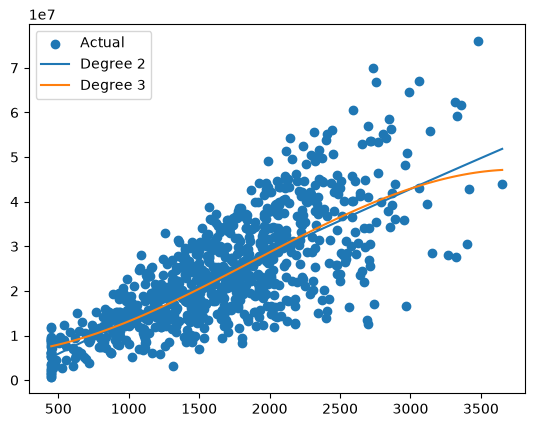

In [14]:
plt.scatter(Xs_test["area_sqft"], ys_test, label="Actual")
for d in [2, 3]:
    model = make_pipeline(PolynomialFeatures(d, include_bias=False), LinearRegression()).fit(Xs_train, ys_train)
    area = np.linspace(Xs_test["area_sqft"].min(), Xs_test["area_sqft"].max(), 100)
    plt.plot(area, model.predict(pd.DataFrame({"area_sqft": area})), label=f"Degree {d}")
plt.legend(); plt.show()

## Part G — Gradient Descent

I compare batch, stochastic, and mini-batch gradient descent using error scores and training time.


In [15]:
x = Xs_train["area_sqft"].to_numpy(float)
yg = ys_train.to_numpy(float)
xt = Xs_test["area_sqft"].to_numpy(float)
xm, xd = x.mean(), x.std() or 1
ym, yd = yg.mean(), yg.std() or 1
x, xt, yg = (x-xm)/xd, (xt-xm)/xd, (yg-ym)/yd
yt = ys_test.to_numpy(float)
def train_gd(method):
    w = b = 0.0; losses = []; start = time.time(); n = len(x)
    for epoch in range(100):
        ids = np.random.permutation(n)
        size = n if method == "Batch" else (1 if method == "SGD" else 32)
        if method == "Batch": ids = np.arange(n)
        for i in range(0, n, size):
            j = ids[i:i+size]; e = w*x[j] + b - yg[j]
            b -= 0.03*2*e.mean(); w -= 0.03*2*(e*x[j]).mean()
        losses.append(np.mean((w*x+b-yg)**2))
    pred = (w*xt+b)*yd+ym
    return losses, mean_absolute_error(yt,pred), np.sqrt(mean_squared_error(yt,pred)), r2_score(yt,pred), time.time()-start
gd = {m: train_gd(m) for m in ["Batch", "SGD", "Mini-Batch"]}

Batch MAE: 6294465.76 RMSE: 8185185.37 R2: 0.562 Time: 0.022 sec
SGD MAE: 6377897.11 RMSE: 8308040.16 R2: 0.549 Time: 6.397 sec
Mini-Batch MAE: 6318558.71 RMSE: 8210672.81 R2: 0.56 Time: 0.209 sec


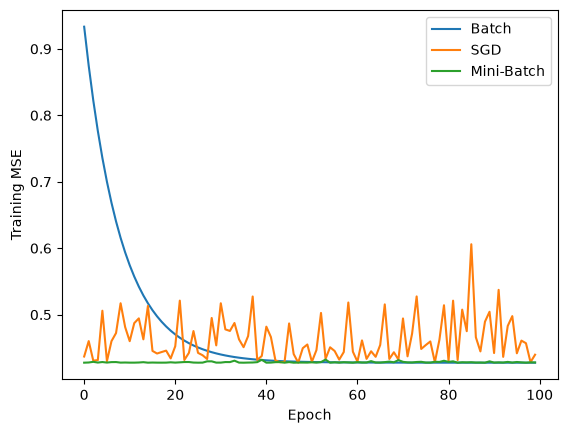

In [16]:
for m, r in gd.items(): print(m, "MAE:", round(r[1], 2), "RMSE:", round(r[2], 2), "R2:", round(r[3], 3), "Time:", round(r[4], 3), "sec")
for m, r in gd.items(): plt.plot(r[0], label=m)
plt.xlabel("Epoch"); plt.ylabel("Training MSE"); plt.legend(); plt.show()

## Part H — Bias and variance

A large training and test error can mean underfitting. A much smaller training error than test error can suggest overfitting.


In [17]:
diagnostics = []
for d in [1, 2, 3, 4]:
    model = make_pipeline(PolynomialFeatures(d, include_bias=False), LinearRegression()).fit(Xs_train, ys_train)
    a = model.predict(Xs_train); b = model.predict(Xs_test)
    diagnostics.append([d, np.sqrt(mean_squared_error(ys_train,a)), np.sqrt(mean_squared_error(ys_test,b))])
diag = pd.DataFrame(diagnostics, columns=["Degree", "Train RMSE", "Test RMSE"])
diag

,Degree,Train RMSE,Test RMSE
0,1,8.104428e+06,8.184697e+06
1,2,8.102913e+06,8.183089e+06
2,3,8.133325e+06,8.206373e+06
3,4,8.323008e+06,8.376997e+06


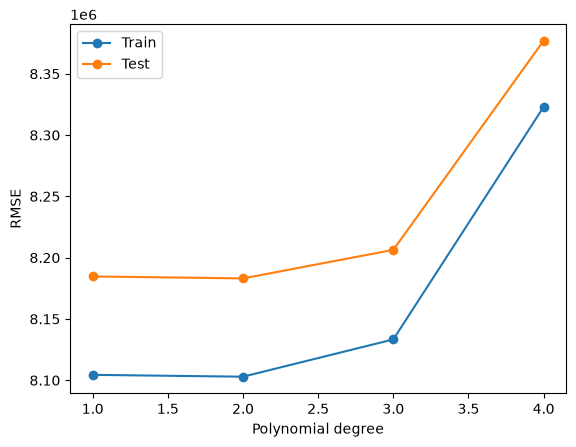

In [18]:
plt.plot(diag["Degree"], diag["Train RMSE"], marker="o", label="Train")
plt.plot(diag["Degree"], diag["Test RMSE"], marker="o", label="Test")
plt.xlabel("Polynomial degree"); plt.ylabel("RMSE"); plt.legend(); plt.show()

## Part I — Final comparison

I use the test scores to decide which model performed best.


In [19]:
final = pd.DataFrame({"Model":["Simple Linear", "Multiple Linear", "Polynomial 2", "Polynomial 3"],
 "RMSE":[rmse_s, rmse_m, poly_df.loc[0,"RMSE"], poly_df.loc[1,"RMSE"]],
 "R2":[r2_s, r2_score(y_test,pred_m), poly_df.loc[0,"R2"], poly_df.loc[1,"R2"]]}).sort_values("RMSE")
final

,Model,RMSE,R2
1,Multiple Linear,3.548650e+06,0.917761
2,Polynomial 2,8.183089e+06,0.562692
0,Simple Linear,8.184697e+06,0.562520
3,Polynomial 3,8.206373e+06,0.560200


### Short report

Use the comparison table above to identify the model with the lowest test RMSE. Check R² as well, and mention the model’s limitations.
